# 01 — Data Exploration and Subset Selection

**Goal:** understand the HarperValleyBank (HVB) data, check its quality, and choose the calls we will process in the rest of the pipeline.

**Input:** `data/raw/metadata/` and `data/raw/transcript/` (created by `python3 scripts/download_data.py`).

**Output:**
- `results/subset_ids.csv` — the calls selected for the pipeline
- `results/figures/` — exploration charts
- `results/data_quality_report.csv` — the quality checks below, as a table

**Sections**
1. Setup
2. Load the data
3. Data-quality checks
4. Descriptive statistics
5. Subset selection
6. Findings

## 1. Setup

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Make the project's src/ package importable from inside notebooks/
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loading import (RAW_DIR, RESULTS_DIR, build_calls_table,
                              build_utterances_table, load_call_ids)

SEED = 42                      # fixed seed: the same subset is chosen on every run
CALLS_PER_TASK = 3             # 8 task types x 3 = 24 calls
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# one simple, consistent chart style for the whole notebook
BAR_COLOR = "#2E5C8A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
pd.set_option("display.max_colwidth", 80)
print("Project root:", PROJECT_ROOT)

Project root: /Users/aa/Projects/call-center-agent-performance-analysis


## 2. Load the data

We build two tables with helper functions from `src/data_loading.py`:
- **`calls`** — one row per call (task, duration, quality ratings, channel layout)
- **`utts`** — one row per utterance (speaker role, timing, human transcript, emotion scores)

In [3]:
call_ids = load_call_ids()
calls = build_calls_table(call_ids)
utts = build_utterances_table(call_ids)

print(f"Calls:      {len(calls):,}")
print(f"Utterances: {len(utts):,}")
calls.head(3)

Calls:      1,446
Utterances: 25,730


,call_id,task_type,n_tasks,duration_s,session,caller_audio_quality,agent_audio_quality,script_adherence,n_utterances,agent_channels,caller_channels,agent_on_channel_1
0,0002f70f7386445b,replace card,1,51.203,Little Harper Valley 3,3.0,3.0,5.0,18,[2],[1],False
1,004860b1ab2e4c88,replace card,1,45.248,Little Harper Valley 2,3.0,3.0,5.0,18,[2],[1],False
2,0091a706bc604188,check balance,1,51.218,Little Harper Valley 2,3.0,3.0,5.0,17,[2],[1],False


In [4]:
utts[["call_id", "index", "speaker_role", "channel_index", "start_s", "end_s",
      "human_transcript", "provider_asr", "emotion_label"]].head(8)

,call_id,index,speaker_role,channel_index,start_s,end_s,human_transcript,provider_asr,emotion_label
0,0002f70f7386445b,1,agent,2,1.669,4.339,hello this is harper valley national bank,hello mr harper valley national bank,positive
1,0002f70f7386445b,2,agent,2,4.839,5.979,my name is elizabeth,my name is alyssa,neutral
2,0002f70f7386445b,3,agent,2,6.469,7.699,how can i help you today,how can i help you today,positive
3,0002f70f7386445b,4,caller,1,12.890,13.220,hi,hi,neutral
4,0002f70f7386445b,5,caller,1,13.720,15.160,my name is patricia brown,my name is patricia brown,positive
5,0002f70f7386445b,6,caller,1,17.420,18.380,i lost my debit card,i lost my debit card,negative
6,0002f70f7386445b,7,caller,1,19.190,20.000,can you send me a new one,can you send me a new one,neutral
7,0002f70f7386445b,8,agent,2,21.539,23.369,which card would you like to replace,which part that you like replace,neutral


## 3. Data-quality checks

Each check answers one question that matters for a later stage of the pipeline:

| Check | Why it matters |
|---|---|
| Every call has metadata **and** transcript files | Missing files would crash later notebooks |
| Every call has exactly one task | The task type is our reference for the summary's "customer issue" |
| Every call has both an agent and a caller | We need both speakers to build a conversation |
| Empty and `[noise]`-only reference segments | They contain no words, so they must be excluded when measuring WER |
| Which channel each role is on | Decides which audio file belongs to the customer |

In [5]:
metadata_files = {p.stem for p in (RAW_DIR / "metadata").glob("*.json")}
transcript_files = {p.stem for p in (RAW_DIR / "transcript").glob("*.json")}
roles_per_call = utts.groupby("call_id")["speaker_role"].nunique()

checks = [
    ("Calls listed in call_ids.txt", len(call_ids)),
    ("Calls missing a metadata file", len(set(call_ids) - metadata_files)),
    ("Calls missing a transcript file", len(set(call_ids) - transcript_files)),
    ("Calls without exactly one task", int((calls["n_tasks"] != 1).sum())),
    ("Calls missing the agent or the caller", int((roles_per_call < 2).sum())),
    ("Utterances with an empty reference", int(utts["is_empty"].sum())),
    ("Utterances that are only '[noise]'", int(utts["is_noise_only"].sum())),
    ("Calls where the agent is on channel 1 (unusual layout)", int(calls["agent_on_channel_1"].sum())),
]
quality = pd.DataFrame(checks, columns=["check", "count"])
quality.to_csv(RESULTS_DIR / "data_quality_report.csv", index=False)
quality

,check,count
0,Calls listed in call_ids.txt,1446
1,Calls missing a metadata file,0
2,Calls missing a transcript file,0
3,Calls without exactly one task,0
4,Calls missing the agent or the caller,0
5,Utterances with an empty reference,349
6,Utterances that are only '[noise]',5672
7,Calls where the agent is on channel 1 (unusual layout),37


### 3.1 Unusual channel layout

In most calls the **caller is on channel 1** and the **agent on channel 2**. The check above found calls where this is reversed.

Two questions follow:
1. Are the **role labels** in the transcript correct for these calls?
2. Which **audio file** holds which channel?

For question 1 we look at who says the bank greeting ("harper valley"). Only the agent should say it.

In [6]:
flipped_ids = calls.loc[calls["agent_on_channel_1"], "call_id"]
greetings = utts[utts["call_id"].isin(flipped_ids) &
                 utts["human_transcript"].str.contains("harper valley")]
first_greeting = greetings.sort_values("start_s").groupby("call_id").first()

print(f"Flipped calls that contain the bank greeting: {len(first_greeting)}")
print("Who says it:")
print(first_greeting["speaker_role"].value_counts().to_string())

Flipped calls that contain the bank greeting: 36
Who says it:
speaker_role
agent    36


In [7]:
# Example: one flipped call, first lines
example_id = flipped_ids.iloc[0]
utts.loc[utts["call_id"] == example_id, ["start_s", "channel_index", "speaker_role", "human_transcript"]].head(6)

,start_s,channel_index,speaker_role,human_transcript
1334,2.705,2,caller,[noise]
1335,6.720,1,agent,hello
1336,7.790,1,agent,this is harper valley national bank
1337,10.390,1,agent,my name is john
1338,12.220,1,agent,how can i help you today
1339,12.635,2,caller,hi my name is james wilson i would like to transfer money between my accounts


For question 2 we need the audio, so it is checked after downloading the subset (section 5.2).

### 3.2 Audio-quality and script-adherence ratings

The dataset authors already removed calls with script adherence below 4 and audio quality below 3 (paper, Section 2.2). We confirm that here.

In [8]:
rating_cols = ["caller_audio_quality", "agent_audio_quality", "script_adherence"]
pd.DataFrame({col: calls[col].value_counts().sort_index() for col in rating_cols}).fillna(0).astype(int)

,caller_audio_quality,agent_audio_quality,script_adherence
3.0,269,191,0
4.0,272,278,210
5.0,905,977,1236


## 4. Descriptive statistics

In [9]:
summary = pd.DataFrame({
    "call duration (s)": calls["duration_s"].describe(),
    "utterances per call": calls["n_utterances"].describe(),
}).round(1)
summary

,call duration (s),utterances per call
count,1446.0,1446.0
mean,59.7,17.8
std,19.6,8.1
min,18.7,3.0
25%,45.4,12.0
50%,56.1,16.0
75%,70.1,21.0
max,181.6,76.0


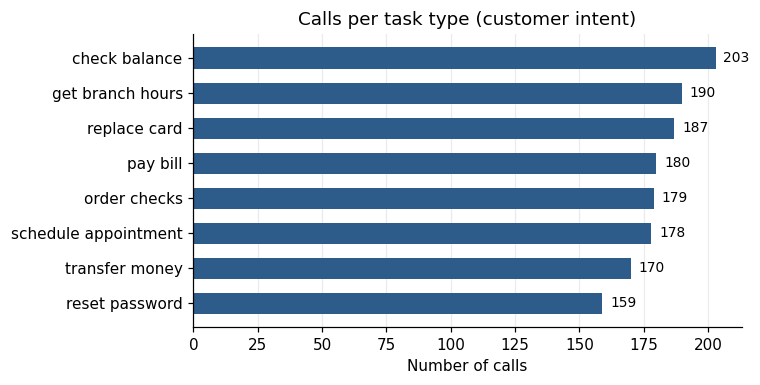

In [10]:
task_counts = calls["task_type"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(task_counts.index, task_counts.values, color=BAR_COLOR, height=0.6)
for y, v in enumerate(task_counts.values):
    ax.text(v + 3, y, str(v), va="center", fontsize=9)
ax.set_title("Calls per task type (customer intent)")
ax.set_xlabel("Number of calls")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_calls_per_task.png")
plt.show()

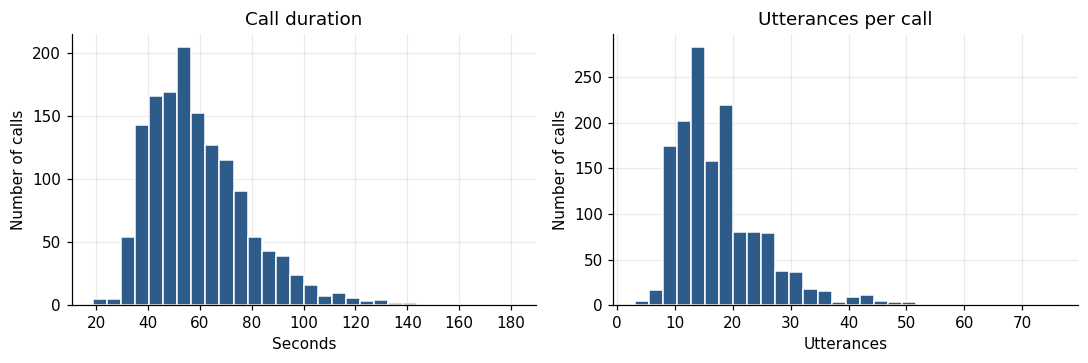

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(calls["duration_s"], bins=30, color=BAR_COLOR, edgecolor="white")
axes[0].set_title("Call duration")
axes[0].set_xlabel("Seconds"); axes[0].set_ylabel("Number of calls")

axes[1].hist(calls["n_utterances"], bins=30, color=BAR_COLOR, edgecolor="white")
axes[1].set_title("Utterances per call")
axes[1].set_xlabel("Utterances"); axes[1].set_ylabel("Number of calls")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_duration_and_utterances.png")
plt.show()

### 4.1 Customer emotion labels in the dataset

These labels come from a **model** (Gridspace API), not from human annotators, so they are only a noisy reference for our own sentiment step. We count **caller** utterances that contain words.

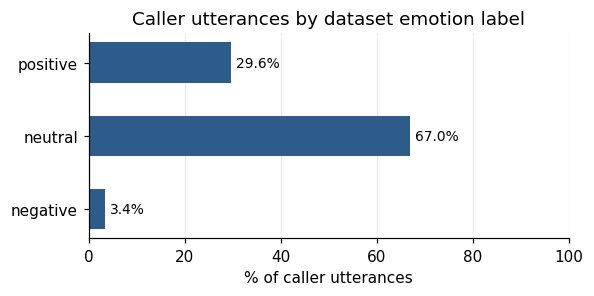

Caller utterances with words: 9,555


In [12]:
caller_speech = utts[(utts["speaker_role"] == "caller") & ~utts["is_empty"] & ~utts["is_noise_only"]]
emotion_share = (caller_speech["emotion_label"].value_counts(normalize=True)
                 .reindex(["negative", "neutral", "positive"]) * 100).round(1)

fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.barh(emotion_share.index, emotion_share.values, color=BAR_COLOR, height=0.55)
for y, v in enumerate(emotion_share.values):
    ax.text(v + 1, y, f"{v}%", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_title("Caller utterances by dataset emotion label")
ax.set_xlabel("% of caller utterances")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_caller_emotion_labels.png")
plt.show()
print(f"Caller utterances with words: {len(caller_speech):,}")

## 5. Subset selection

**Why a subset?** Running speech recognition and a language model on all 1,446 calls is not needed to evaluate the pipeline and does not fit the time budget. We process a smaller set and evaluate it carefully.

**How we choose it**
- **Stratified by task type:** {CALLS_PER_TASK} calls from each of the 8 intents, so every kind of customer issue is represented (24 calls).
- **Random within each task**, with a fixed seed (`SEED = 42`) so anyone gets the same calls.
- **No filtering on audio quality**, so the subset reflects the real mix of easy and hard calls.
- **Plus one deliberate edge case:** one call with the unusual channel layout, to test that our speaker-role logic handles it. It is marked in the `selection_reason` column.

In [13]:
stratified = (calls.groupby("task_type", group_keys=False)
                   .sample(n=CALLS_PER_TASK, random_state=SEED))
stratified = stratified.assign(selection_reason="stratified random")

already_has_flipped = stratified["agent_on_channel_1"].any()
if already_has_flipped:
    subset = stratified
else:
    edge_case = (calls[calls["agent_on_channel_1"]]
                 .sample(n=1, random_state=SEED)
                 .assign(selection_reason="edge case: agent on channel 1"))
    subset = pd.concat([stratified, edge_case])

subset = subset.sort_values(["task_type", "call_id"]).reset_index(drop=True)
subset_cols = ["call_id", "task_type", "duration_s", "n_utterances",
               "caller_audio_quality", "agent_on_channel_1", "selection_reason"]
subset[subset_cols].to_csv(RESULTS_DIR / "subset_ids.csv", index=False)

print(f"Selected calls: {len(subset)}  |  total audio: {subset['duration_s'].sum() / 60:.1f} min per side")
subset[subset_cols]

Selected calls: 25  |  total audio: 25.4 min per side


,call_id,task_type,duration_s,n_utterances,caller_audio_quality,agent_on_channel_1,selection_reason
0,08f360b3f3b844ef,check balance,66.610,17,5.0,False,stratified random
1,0dee81761a5c45f9,check balance,71.526,12,4.0,False,stratified random
2,7f3d383f8aff498d,check balance,54.332,16,5.0,True,edge case: agent on channel 1
3,8c86097e491544df,check balance,41.156,13,5.0,False,stratified random
4,37a7a35a1e244820,get branch hours,48.063,10,5.0,False,stratified random
5,51cb5e31125c4235,get branch hours,40.030,10,5.0,False,stratified random
6,9e05bd9ca9564089,get branch hours,24.754,3,5.0,False,stratified random
7,09fc75fc02ea4b46,order checks,75.769,16,5.0,False,stratified random
8,0f87dc392db84250,order checks,66.701,16,4.0,False,stratified random
9,a35cc473b91f4de0,order checks,66.869,22,4.0,False,stratified random


In [14]:
# Is the subset similar to the full dataset?
comparison = pd.DataFrame({
    "full dataset": [calls["duration_s"].median(), calls["n_utterances"].median(),
                     (calls["caller_audio_quality"] == 5).mean() * 100],
    "subset": [subset["duration_s"].median(), subset["n_utterances"].median(),
               (subset["caller_audio_quality"] == 5).mean() * 100],
}, index=["median duration (s)", "median utterances", "% calls with caller audio quality 5"]).round(1)
comparison

,full dataset,subset
median duration (s),56.1,54.3
median utterances,16.0,15.0
% calls with caller audio quality 5,62.6,56.0


### 5.1 Download the subset audio

Run this in the terminal from the project root (it downloads only the selected calls):

```bash
python3 scripts/download_data.py --audio results/subset_ids.csv
```

### 5.2 Which audio file holds which channel?

After the download, we test it directly: during the moments when **channel 1** speaks (according to the transcript timestamps), the `caller/` file should be louder than during channel 2 speech. We measure loudness as RMS (root mean square) of the samples.

In [15]:
import wave
import numpy as np
from src.data_loading import RAW_DIR

def rms_during(wav_path, segments):
    """RMS loudness of a WAV file inside the given (start_s, end_s) segments."""
    with wave.open(str(wav_path)) as w:
        rate = w.getframerate()
        samples = np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16).astype(float)
    pieces = [samples[int(s * rate):int(e * rate)] for s, e in segments]
    pieces = [p for p in pieces if len(p)]
    return float(np.sqrt(np.mean(np.concatenate(pieces) ** 2))) if pieces else 0.0

rows = []
for call_id in subset["call_id"]:
    caller_file = RAW_DIR / "audio" / "caller" / f"{call_id}.wav"
    if not caller_file.exists():
        continue
    speech = utts[(utts["call_id"] == call_id) & ~utts["is_empty"] & ~utts["is_noise_only"]]
    seg = lambda ch: speech.loc[speech["channel_index"] == ch, ["start_s", "end_s"]].values
    rows.append({"call_id": call_id,
                 "caller_file_rms_during_ch1": round(rms_during(caller_file, seg(1))),
                 "caller_file_rms_during_ch2": round(rms_during(caller_file, seg(2)))})

channel_check = pd.DataFrame(rows)
if channel_check.empty:
    print("Audio not downloaded yet: run the command in 5.1, then re-run this cell.")
else:
    channel_check["caller_file_is_channel_1"] = (channel_check["caller_file_rms_during_ch1"]
                                                 > channel_check["caller_file_rms_during_ch2"])
    print(f"caller/ file holds channel 1 in {channel_check['caller_file_is_channel_1'].sum()}"
          f" of {len(channel_check)} calls")
    display(channel_check)

caller/ file holds channel 1 in 25 of 25 calls


,call_id,caller_file_rms_during_ch1,caller_file_rms_during_ch2,caller_file_is_channel_1
0,08f360b3f3b844ef,3901,1661,True
1,0dee81761a5c45f9,2674,4,True
2,7f3d383f8aff498d,1193,612,True
3,8c86097e491544df,2075,865,True
4,37a7a35a1e244820,1518,20,True
5,51cb5e31125c4235,1802,760,True
6,9e05bd9ca9564089,2212,5,True
7,09fc75fc02ea4b46,1481,46,True
8,0f87dc392db84250,1512,5,True
9,a35cc473b91f4de0,3697,710,True


## 6. Findings

These findings come from the outputs above (full dataset unless stated).

**Completeness**
- All 1,446 calls have a metadata file and a transcript file; none are missing or unreadable.
- Every call has exactly one task and contains both an agent and a caller.

**Reference transcripts**
- 22% of utterances are only `[noise]` and 1.4% are empty. They contain no spoken words, so they are **excluded from the reference text when we compute WER** (notebook 02).

**Channel layout (important for speaker roles)**
- In 37 calls (2.6%) the agent is on channel 1 instead of channel 2.
- In every one of these calls that contains the bank greeting (36 of 36), the greeting is labelled `agent`, so the **transcript role labels are correct**.
- The audio check in 5.2 shows the `caller/` file always holds **channel 1**. So in these 37 calls the agent's voice is stored in the `caller/` folder.
- Some files also contain the **other speaker faintly** (echo or crosstalk). For example, in call `08f360b3f3b844ef` the `caller/` file still has RMS 1661 while the agent speaks, against 3901 while the caller speaks. Speech recognition may transcribe this leaked speech, so notebook 02 must check for it.
- **Decision:** we never assume a role from the folder name. We map *audio file → channel → role*, with the role taken from the transcript (`src/data_loading.audio_path`).

**Dataset emotion labels**
- Caller utterances are mostly neutral (67.0%), then positive (29.6%), and rarely negative (3.4%). These are model outputs, not human labels.
- Expect our customer sentiment results to be dominated by Neutral; overall accuracy alone would be misleading, so notebook 05 also reviews examples by hand.

**Subset**
- 25 calls: 24 stratified random (3 per task type, seed 42) + 1 edge case with the unusual channel layout.
- The subset is close to the full dataset on median duration (54.3 s vs 56.1 s) and median utterances (15 vs 16). It has slightly fewer calls with the top caller audio rating (56% vs 63%), so it is not easier than the full data.

**Limitations**
- The calls are scripted role-play with a small vocabulary, so results will not fully transfer to real call-center audio.
- 25 calls is enough to test and inspect the pipeline, not to report precise accuracy for the whole dataset.